# Overnight/Daytime Sign Agreement and Last-Half-Hour Momentum, CL 2021–2026 (#33)

This notebook collects the outputs of `src/analyze_sign_agreement.py`: the four ON/DAY sign categories, the two-dimensional (ON, DAY) view, the agreement regressions, their out-of-sample performance, the sign-filtered trading strategies and the robustness checks. It reads only the files the script writes and computes nothing the script does not. Run the script first, from the repository root:

```bash
python -m src.analyze_sign_agreement --config config/sign_agreement.yaml
```

The write-up is `reports/sign_agreement_results.md`. Means are in basis points with Newey-West standard errors from indicator regressions on the chronological sample; slopes are × 100. Zero-return days are set aside from every comparison and regression.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = next(path for path in (Path("."), Path("..")) if (path / "reports/tables").exists())
tables = root / "reports/tables"
figures = root / "reports/figures"

manifest = json.loads((tables / "sign_agreement.manifest.json").read_text())
categories = pd.read_csv(tables / "sign_agreement_categories.csv")
grid = pd.read_csv(tables / "sign_agreement_grid.csv")
regressions = pd.read_csv(tables / "sign_agreement_regressions.csv")
oos = pd.read_csv(tables / "sign_agreement_oos.csv")
strategies = pd.read_csv(tables / "sign_agreement_strategies.csv")
by_year = pd.read_csv(tables / "sign_agreement_by_year.csv")
robustness = pd.read_csv(tables / "sign_agreement_robustness.csv")
robustness_terms = pd.read_csv(tables / "sign_agreement_robustness_regressions.csv")
robustness_models = pd.read_csv(tables / "sign_agreement_robustness_models.csv")

pd.set_option("display.float_format", lambda value: f"{value:,.3f}")


def estimate(frame: pd.DataFrame, value: str, error: str) -> pd.Series:
	return frame.apply(lambda row: f"{row[value]:.2f} ({row[error]:.2f})" if pd.notna(row[value]) else "", axis=1)

## 1. Sample and categories

Signs of ON (previous 13:30 to 08:00 CT) and DAY (08:00 to 13:00 CT) are known at 13:00 CT. The four categories, the pooled agreement and disagreement groups, the zero-return days (reported, not used), and the agree-minus-disagree difference in the paper's strategy return η = sign(ROD) × LH. Hit rates exclude days with LH exactly zero.

In [2]:
pd.Series(
	{
		"trade dates": manifest["sample"]["observations"],
		"dates": manifest["sample"]["dates"],
		"zero-return days (set aside)": manifest["sample"]["zero_return_days"],
		"dates in the regressions": manifest["sample"]["regression_observations"],
		"days with LH exactly zero (neither hit nor miss)": manifest["sample"]["lh_zero_days"],
		"category counts": manifest["category_counts"],
		"Newey-West lags": manifest["hac_lags_used"],
		"first out-of-sample forecast": manifest["sample"]["first_oos_forecast"],
		"exploratory Bonferroni level (5 defined comparisons)": f"{manifest['bonferroni_level']:.3f}",
	},
	name="value",
).to_frame()

,value
trade dates,1436
dates,2021-01-04 to 2026-10-07
zero-return days (set aside),12
dates in the regressions,1424
days with LH exactly zero (neither hit nor miss),21
category counts,"{'ON+/DAY+': 415, 'ON+/DAY-': 377, 'ON-/DAY+':..."
Newey-West lags,7
first out-of-sample forecast,2023-01-06
exploratory Bonferroni level (5 defined comparisons),0.010


In [3]:
table = categories.assign(mean_lh=estimate(categories, "mean_lh_bps", "se_lh_bps"), eta=estimate(categories, "eta_bps", "se_eta_bps"))
table[["group", "kind", "n", "mean_lh", "sd_lh_pct", "lh_follows_rod", "lh_follows_rod_se", "decided_days", "eta", "ci_low_eta_bps", "ci_high_eta_bps", "t_eta", "p_eta"]].rename(
	columns={"mean_lh": "mean LH bps (SE)", "eta": "sign(ROD) x LH bps (SE)"}
)

,group,kind,n,mean LH bps (SE),sd_lh_pct,lh_follows_rod,lh_follows_rod_se,decided_days,sign(ROD) x LH bps (SE),ci_low_eta_bps,ci_high_eta_bps,t_eta,p_eta
0,ON+/DAY+,category,415,-4.11 (1.94),0.438,0.477,0.025,409,-4.11 (1.94),-7.899,-0.313,-2.122,NaN
1,ON-/DAY-,category,305,5.00 (3.01),0.562,0.470,0.029,304,-5.00 (3.01),-10.891,0.897,-1.662,NaN
2,ON+/DAY-,category,377,-3.69 (2.30),0.447,0.515,0.026,373,2.10 (2.34),-2.489,6.691,0.897,NaN
3,ON-/DAY+,category,327,-1.07 (2.42),0.433,0.476,0.028,317,1.62 (2.39),-3.056,6.305,0.680,NaN
4,agree,pooled,720,-0.25 (1.66),0.496,0.474,0.019,713,-4.48 (1.72),-7.860,-1.107,-2.602,NaN
5,disagree,pooled,704,-2.47 (1.64),0.441,0.497,0.019,690,1.88 (1.72),-1.493,5.253,1.092,NaN
6,zero,excluded,12,-9.97 (11.76),0.425,0.667,0.136,12,16.96 (11.07),-4.747,38.665,1.531,NaN
7,agree - disagree,difference,1424,,NaN,-0.023,0.025,1403,-6.36 (2.34),-10.950,-1.777,-2.719,0.007


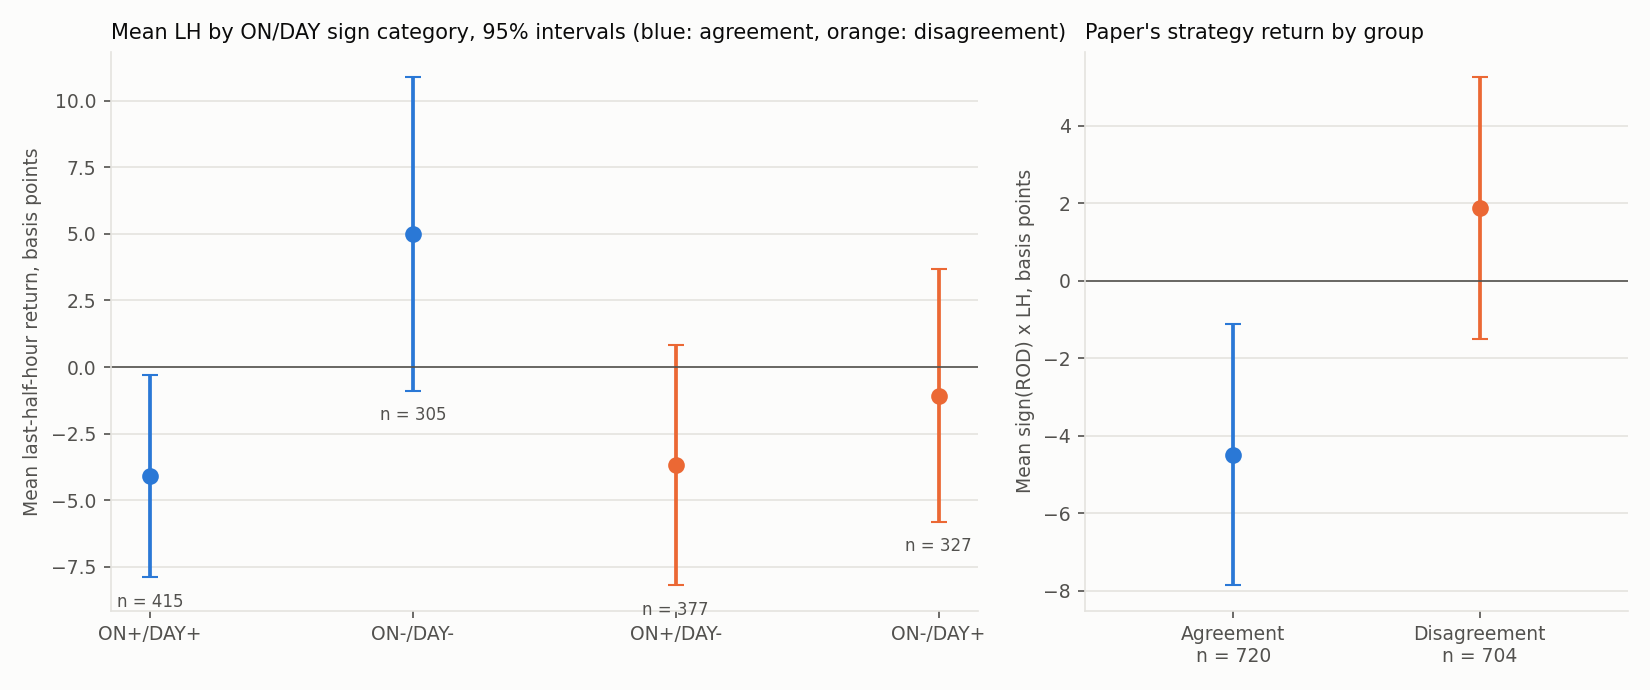

In [4]:
display(Image(filename=figures / "sign_agreement_categories.png", width=950))

## 2. The two-dimensional view

ON and DAY as a vector: mean LH and the strategy return η on the tercile grid, and the regressions with the ON × DAY product (a nonlinear, sign-symmetric term) and the agreement interactions (the directional terms).

In [5]:
grid.assign(mean_lh=estimate(grid, "mean_lh_bps", "se_lh_bps")).pivot(index="on_bin", columns="day_bin", values="mean_lh").reindex(index=["high", "mid", "low"], columns=["low", "mid", "high"])

day_bin,low,mid,high
on_bin,,,
high,-8.17 (3.83),0.39 (3.08),-5.55 (3.76)
mid,2.73 (3.74),-1.07 (3.03),-7.07 (3.12)
low,6.93 (4.65),0.35 (3.77),-1.22 (3.65)


In [6]:
grid.assign(eta=estimate(grid, "eta_bps", "se_eta_bps")).pivot(index="on_bin", columns="day_bin", values="eta").reindex(index=["high", "mid", "low"], columns=["low", "mid", "high"])

day_bin,low,mid,high
on_bin,,,
high,7.91 (4.04),0.39 (3.08),-5.55 (3.76)
mid,-2.86 (3.75),-0.88 (3.10),-7.07 (3.12)
low,-6.93 (4.65),0.69 (3.76),2.96 (3.22)


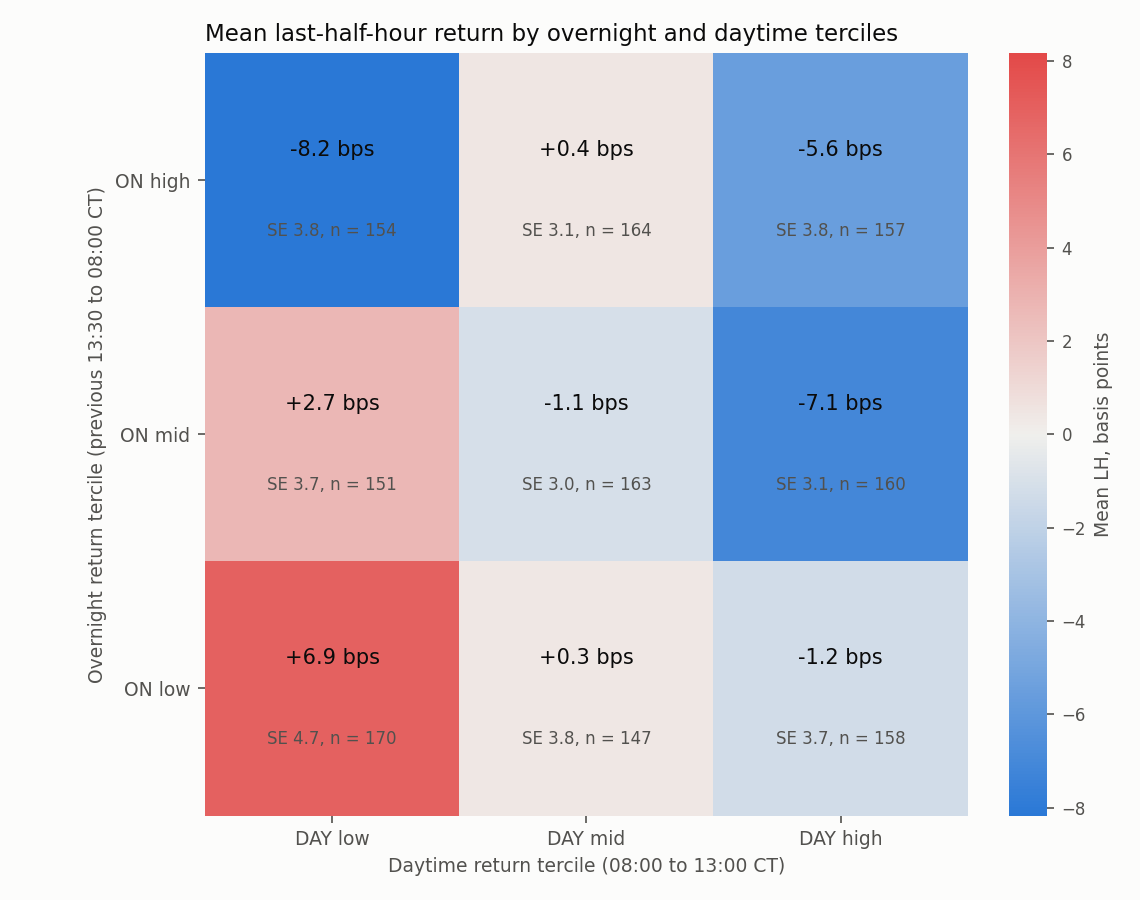

In [7]:
display(Image(filename=figures / "sign_agreement_grid.png", width=640))

In [8]:
fit = regressions.assign(estimate=estimate(regressions, "coef_x100", "se_x100"))
fit[["model", "term", "estimate", "ci_low_x100", "ci_high_x100", "t_stat", "p_value", "n", "adj_r2_pct"]].rename(columns={"estimate": "coef x 100 (SE)"})

,model,term,coef x 100 (SE),ci_low_x100,ci_high_x100,t_stat,p_value,n,adj_r2_pct
0,rod,const,-0.01 (0.01),-0.035,0.013,-0.934,0.351,1424,0.549
1,rod,rod,-1.48 (0.97),-3.379,0.410,-1.536,0.125,1424,0.549
2,rod_by_agreement,const,-0.02 (0.02),-0.057,0.007,-1.506,0.132,1424,1.687
3,rod_by_agreement,rod,2.29 (1.25),-0.156,4.727,1.834,0.067,1424,1.687
4,rod_by_agreement,agree,0.03 (0.02),-0.019,0.078,1.196,0.232,1424,1.687
5,rod_by_agreement,rod_x_agree,-4.93 (1.61),-8.090,-1.762,-3.051,0.002,1424,1.687
6,on_day,const,-0.01 (0.01),-0.036,0.012,-0.953,0.340,1424,0.545
7,on_day,on,-1.29 (1.01),-3.272,0.693,-1.274,0.203,1424,0.545
8,on_day,day,-1.87 (1.44),-4.682,0.947,-1.300,0.193,1424,0.545
9,on_day_product,const,-0.01 (0.01),-0.033,0.014,-0.828,0.407,1424,1.914


## 3. Out of sample

Expanding-window forecasts after 500 observations on the 1,424 regression dates, against the historical mean and against the model each interaction model nests (Clark-West).

In [9]:
oos[["model", "n", "adj_r2_pct", "wald_df", "wald_p", "oos_forecasts", "first_forecast", "oos_r2_pct", "clark_west_t", "clark_west_p", "nested_in", "oos_r2_vs_nested_pct", "clark_west_t_vs_nested", "clark_west_p_vs_nested"]]

,model,n,adj_r2_pct,wald_df,wald_p,oos_forecasts,first_forecast,oos_r2_pct,clark_west_t,clark_west_p,nested_in,oos_r2_vs_nested_pct,clark_west_t_vs_nested,clark_west_p_vs_nested
0,rod,1424,0.549,NaN,NaN,924,2023-01-06,0.433,1.070,0.142,NaN,NaN,NaN,NaN
1,rod_by_agreement,1424,1.687,1.000,0.002,924,2023-01-06,0.815,1.637,0.051,rod,0.384,1.562,0.059
2,on_day,1424,0.545,NaN,NaN,924,2023-01-06,-0.205,0.483,0.315,NaN,NaN,NaN,NaN
3,on_day_product,1424,1.914,1.000,0.021,924,2023-01-06,-0.415,0.712,0.238,on_day,-0.209,0.784,0.216
4,on_day_by_agreement,1424,2.456,2.000,0.005,924,2023-01-06,-0.218,1.037,0.150,on_day,-0.012,1.213,0.113


## 4. Trading comparison

Sign-filtered strategies priced with the #30 baseline execution variant and costs. The baseline row reproduces the #30 result.

In [10]:
strategies.assign(mean=estimate(strategies, "mean_bps", "se_hac_bps"), sharpe=estimate(strategies, "sharpe", "sharpe_se"))[
	["strategy", "accounting", "traded_days", "mean", "ci_low_bps", "ci_high_bps", "sharpe", "hit_rate", "total_pnl_usd", "max_drawdown_usd", "total_cost_usd"]
].rename(columns={"mean": "mean bps (SE)", "sharpe": "Sharpe (SE)"})

,strategy,accounting,traded_days,mean bps (SE),ci_low_bps,ci_high_bps,Sharpe (SE),hit_rate,total_pnl_usd,max_drawdown_usd,total_cost_usd
0,rod,frictionless,1435,-1.18 (1.26),-3.656,1.287,-0.40 (0.42),0.480,NaN,NaN,NaN
1,rod,gross,1435,-1.15 (1.26),-3.621,1.319,-0.39 (0.42),0.481,"-9,570.000","23,380.000","21,525.000"
2,rod,net,1435,-3.15 (1.26),-5.621,-0.677,-1.07 (0.42),0.466,"-31,095.000","39,235.000","21,525.000"
3,agree_only,frictionless,720,-2.25 (0.87),-3.948,-0.548,-1.02 (0.42),0.469,NaN,NaN,NaN
4,agree_only,gross,720,-2.19 (0.87),-3.899,-0.489,-0.99 (0.42),0.474,"-24,850.000","29,030.000","10,800.000"
5,agree_only,net,720,-3.19 (0.87),-4.904,-1.485,-1.44 (0.42),0.457,"-35,650.000","39,055.000","10,800.000"
6,disagree_only,frictionless,703,0.92 (0.84),-0.734,2.577,0.47 (0.42),0.488,NaN,NaN,NaN
7,disagree_only,gross,703,0.90 (0.84),-0.754,2.549,0.46 (0.42),0.485,"13,600.000","6,480.000","10,545.000"
8,disagree_only,net,703,-0.08 (0.84),-1.733,1.567,-0.04 (0.42),0.471,"3,055.000","11,685.000","10,545.000"
9,day_sign,frictionless,1432,-1.45 (1.14),-3.691,0.783,-0.49 (0.42),0.484,NaN,NaN,NaN


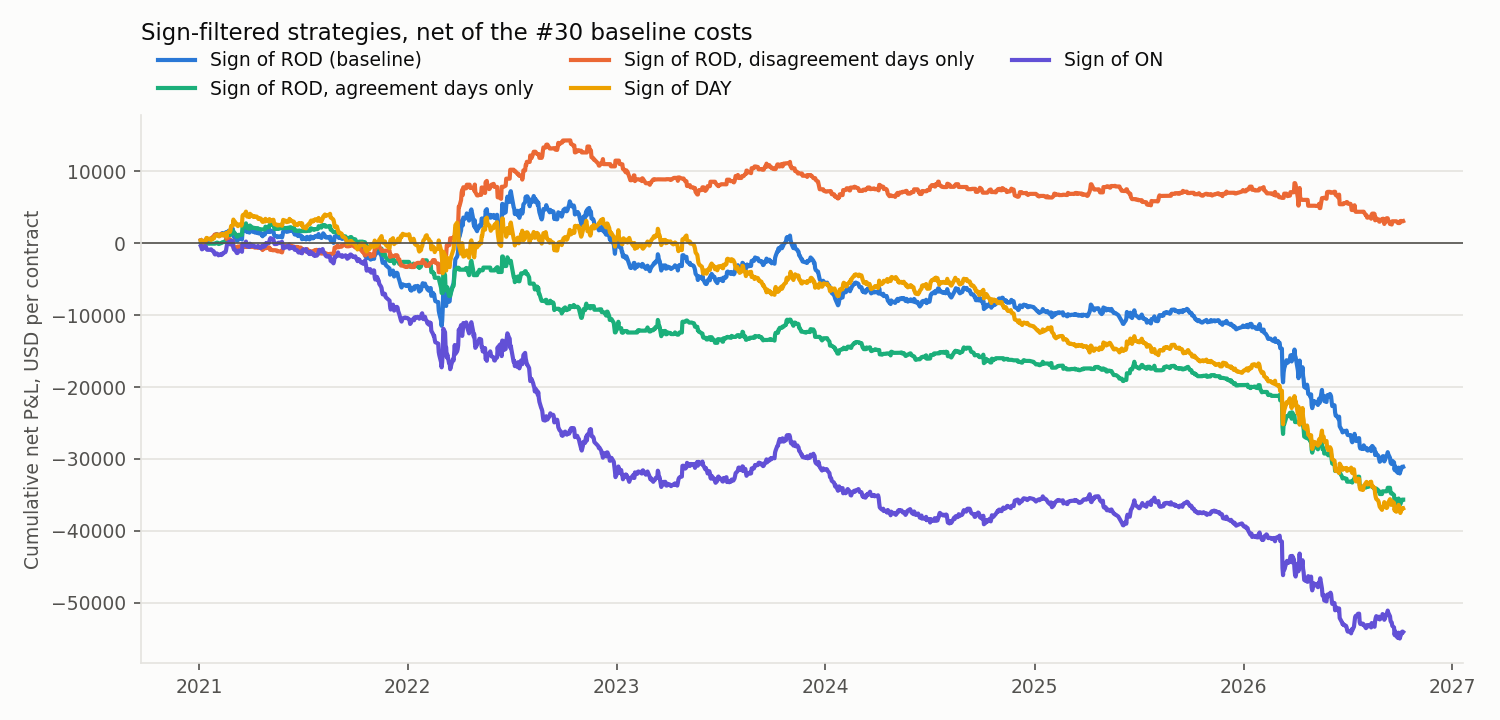

In [11]:
display(Image(filename=figures / "sign_agreement_cumulative.png", width=950))

## 5. Stability and robustness

By calendar year; then each robustness variant (excluded dates, the pre-expiry roll rule, log returns, the zero-day coding) with the agree-minus-disagree difference, the interaction slopes and the agreement model's out-of-sample statistics.

In [12]:
by_year.assign(eta=estimate(by_year, "eta_bps", "se_eta_bps"))[["year", "group", "n", "eta", "t_eta", "lh_follows_rod"]].rename(columns={"eta": "sign(ROD) x LH bps (SE)"})

,year,group,n,sign(ROD) x LH bps (SE),t_eta,lh_follows_rod
0,2021,agree,114,-0.57 (3.87),-0.147,0.496
1,2021,disagree,136,-0.74 (3.27),-0.225,0.489
2,2021,agree - disagree,250,0.17 (5.31),0.031,NaN
3,2022,agree,128,-7.63 (5.20),-1.469,0.465
4,2022,disagree,119,13.49 (6.53),2.065,0.563
5,2022,agree - disagree,247,-21.12 (7.69),-2.746,NaN
6,2023,agree,129,0.42 (3.94),0.106,0.535
7,2023,disagree,117,-3.16 (3.84),-0.823,0.452
8,2023,agree - disagree,246,3.58 (4.98),0.719,NaN
9,2024,agree,124,-2.34 (2.83),-0.825,0.471


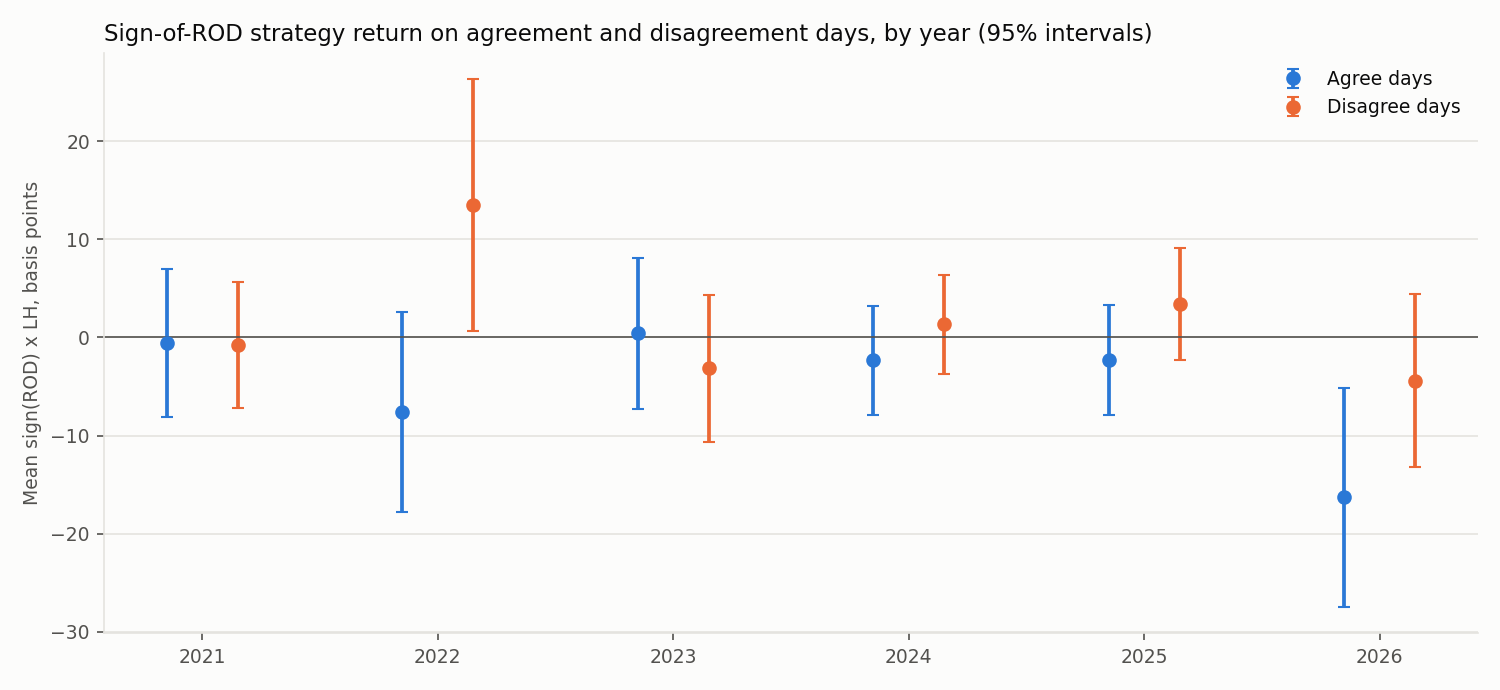

In [13]:
display(Image(filename=figures / "sign_agreement_by_year.png", width=950))

In [14]:
difference = robustness[robustness["group"].eq("agree - disagree")].assign(difference=estimate(robustness, "eta_bps", "se_eta_bps"))[["variant", "dropped", "n", "difference", "p_eta"]]
interactions = robustness_terms[robustness_terms["term"].isin(["rod_x_agree", "day_x_agree", "on_x_day"])].assign(estimate=estimate(robustness_terms, "coef_x100", "se_x100"))
agreement_oos = robustness_models[robustness_models["model"].eq("rod_by_agreement")].set_index("variant")[["oos_r2_pct", "clark_west_p", "oos_r2_vs_nested_pct", "clark_west_p_vs_nested"]]
difference.merge(interactions.pivot(index="variant", columns="term", values="estimate"), on="variant", how="outer").merge(agreement_oos, on="variant", how="outer").rename(
	columns={"difference": "agree - disagree bps (SE)", "oos_r2_pct": "ROD+Agree OOS R2 %", "clark_west_p": "CW p", "oos_r2_vs_nested_pct": "vs ROD %", "clark_west_p_vs_nested": "CW p vs ROD"}
)

,variant,dropped,n,agree - disagree bps (SE),p_eta,day_x_agree,on_x_day,rod_x_agree,ROD+Agree OOS R2 %,CW p,vs ROD %,CW p vs ROD
0,exclude:exclude_2022_and_2026,441.000,987.000,-1.41 (2.32),0.543,-3.49 (2.74),-66.25 (56.67),-0.75 (1.63),-1.264,0.903,-0.890,0.959
1,exclude:exclude_2026_03_10,1.000,"1,423.000",-5.74 (2.27),0.011,-7.51 (2.52),46.09 (37.99),-3.93 (1.39),-0.468,0.109,-0.448,0.116
2,exclude:exclude_after_non_trading_days,304.000,"1,124.000",-6.73 (2.69),0.012,-11.36 (4.09),140.28 (81.29),-6.18 (1.84),1.338,0.015,1.647,0.032
3,exclude:exclude_degraded_dates,12.000,"1,412.000",-6.89 (2.38),0.004,-9.90 (3.44),108.49 (46.77),-5.10 (1.64),1.042,0.043,0.500,0.054
4,exclude:exclude_roll_dates,69.000,"1,355.000",-7.18 (2.37),0.002,-10.92 (3.53),118.00 (48.34),-5.34 (1.62),0.725,0.056,0.583,0.043
5,include_zero_return_days,NaN,NaN,NaN,NaN,-10.06 (3.43),108.37 (46.94),-5.00 (1.60),0.746,0.052,0.380,0.056
6,log_returns,0.000,"1,424.000",-6.36 (2.34),0.007,-10.07 (3.45),113.38 (46.92),-5.01 (1.63),0.905,0.050,0.472,0.059
7,pre_expiry_roll_3_sessions,0.000,"1,423.000",-6.55 (2.33),0.005,-9.99 (3.48),108.20 (46.88),-4.98 (1.61),0.806,0.052,0.360,0.060
